In [ ]:
!pip install -q -U yfinance


In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint


In [ ]:
import os
path = '/content/data'
os.makedirs(path, exist_ok=True)

In [ ]:
tickers = ["TCS.NS", "INFY.NS", "WIPRO.NS", "HCLTECH.NS", "TECHM.NS"]
prices = yf.download(tickers, start="2017-01-01", end="2026-10-01",
                     auto_adjust=True)["Close"]
prices = prices.dropna()
prices.to_csv(f"{path}/it_prices.csv")
print(prices.shape)
prices.tail()

[*********************100%***********************]  5 of 5 completed


(2409, 5)


Ticker,HCLTECH.NS,INFY.NS,TCS.NS,TECHM.NS,WIPRO.NS
Date,,,,,
2026-09-24,1243.599976,1014.500000,2087.000000,1543.000000,163.639999
2026-09-25,1258.000000,1000.200012,2082.000000,1548.000000,164.020004
2026-09-28,1252.599976,1003.200012,2070.699951,1542.199951,161.559998
2026-09-29,1222.000000,1015.400024,2032.400024,1510.500000,156.789993
2026-09-30,1230.000000,994.099976,2050.600098,1524.000000,158.500000


Ticker
HCLTECH.NS    0
INFY.NS       1
TCS.NS        0
TECHM.NS      1
WIPRO.NS      1
dtype: int64


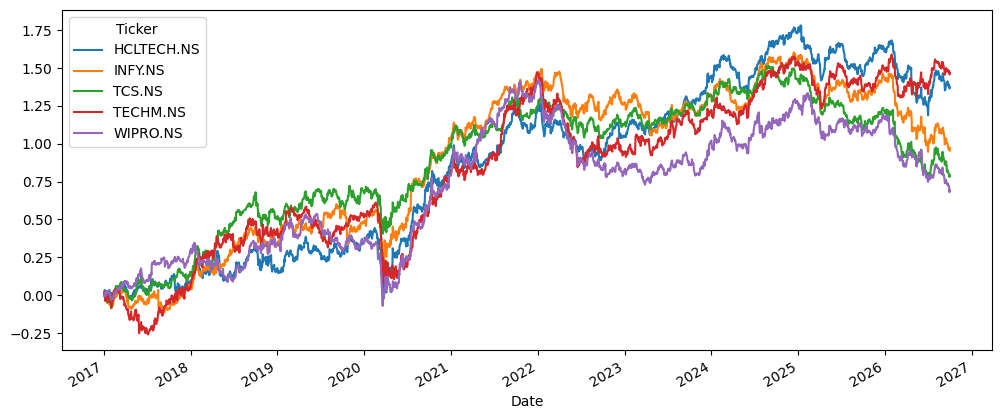

In [ ]:
logp = np.log(prices)
print((logp.diff().abs() > 0.15).sum())
(logp - logp.iloc[0]).plot(figsize=(12, 5))
plt.show()


In [ ]:
big = logp.diff().abs() > 0.15
for s in big.columns:
    print(s, list(big.index[big[s]].date))

HCLTECH.NS []
INFY.NS [datetime.date(2019, 10, 22)]
TCS.NS []
TECHM.NS [datetime.date(2020, 3, 23)]
WIPRO.NS [datetime.date(2020, 7, 15)]


In [ ]:
from itertools import combinations

form = logp.loc["2017-01-01":"2018-12-31"]

results = []
for a, b in combinations(form.columns, 2):
    score, pvalue, _ = coint(form[a], form[b])
    results.append((a, b, round(pvalue, 3)))

pd.DataFrame(results, columns=["Stock A", "Stock B", "p-value"]).sort_values("p-value")

,Stock A,Stock B,p-value
1,HCLTECH.NS,TCS.NS,0.006
4,INFY.NS,TCS.NS,0.006
0,HCLTECH.NS,INFY.NS,0.008
2,HCLTECH.NS,TECHM.NS,0.015
7,TCS.NS,TECHM.NS,0.211
5,INFY.NS,TECHM.NS,0.385
3,HCLTECH.NS,WIPRO.NS,0.393
9,TECHM.NS,WIPRO.NS,0.871
8,TCS.NS,WIPRO.NS,0.878
6,INFY.NS,WIPRO.NS,0.885


Hedge ratio: 0.771
Theta: 0.0638
Half-life (days): 10.9


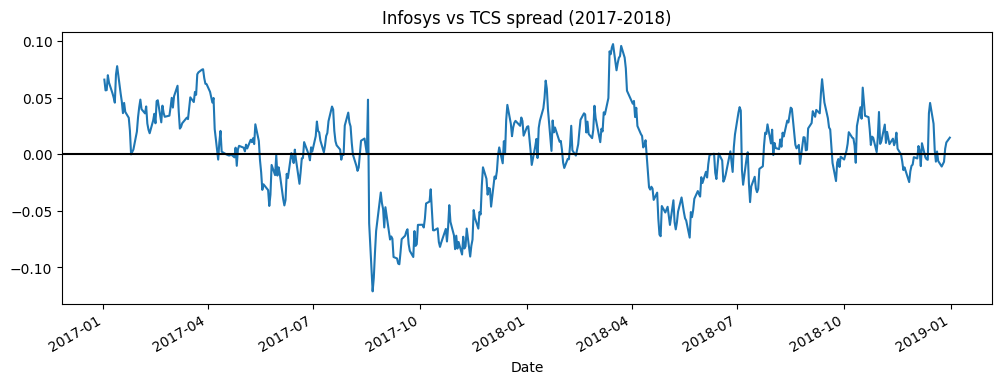

In [ ]:
a, b = "INFY.NS", "TCS.NS"
y = form[a]
x = form[b]

# hedge ratio
h, c = np.polyfit(x, y, 1)
spread = y - h*x - c
print("Hedge ratio:", round(h, 3))

# how fast the spread snaps back
ds = spread.diff().dropna()
lag = spread.shift(1).dropna()
slope, intercept = np.polyfit(lag, ds, 1)
theta = -np.log(1 + slope)
half_life = np.log(2) / theta
print("Theta:", round(theta, 4))
print("Half-life (days):", round(half_life, 1))

spread.plot(figsize=(12, 4), title="Infosys vs TCS spread (2017-2018)")
plt.axhline(0, color="black")
plt.show()

Average gap: -0.0017
Typical size of gap: 0.04


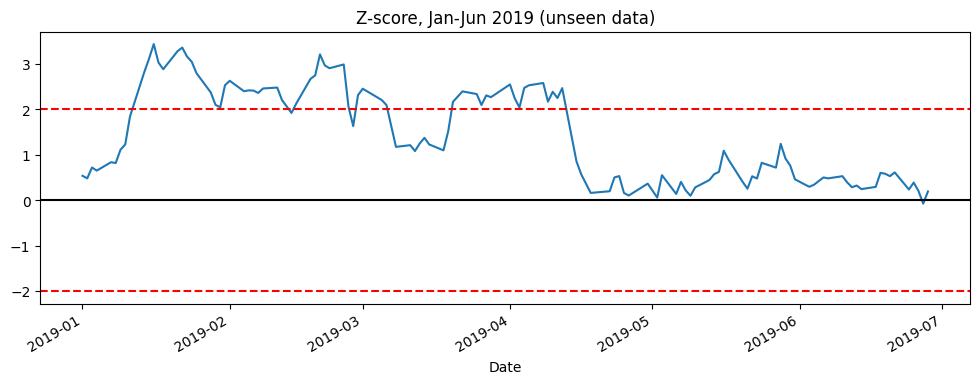

In [ ]:
# numbers learned from 2017-2018
mu = -intercept / slope
resid = ds - (intercept + slope * lag)
sigma_eq = resid.std() / np.sqrt(1 - np.exp(-2 * theta))
print("Average gap:", round(mu, 4))
print("Typical size of gap:", round(sigma_eq, 4))

# apply them to the next 6 months
test = logp.loc["2019-01-01":"2019-06-30"]
spread_test = test[a] - h * test[b] - c
z = (spread_test - mu) / sigma_eq

z.plot(figsize=(12, 4), title="Z-score, Jan-Jun 2019 (unseen data)")
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")
plt.axhline(0, color="black")
plt.show()

Total profit: 10.61 %
Days in a trade: 63


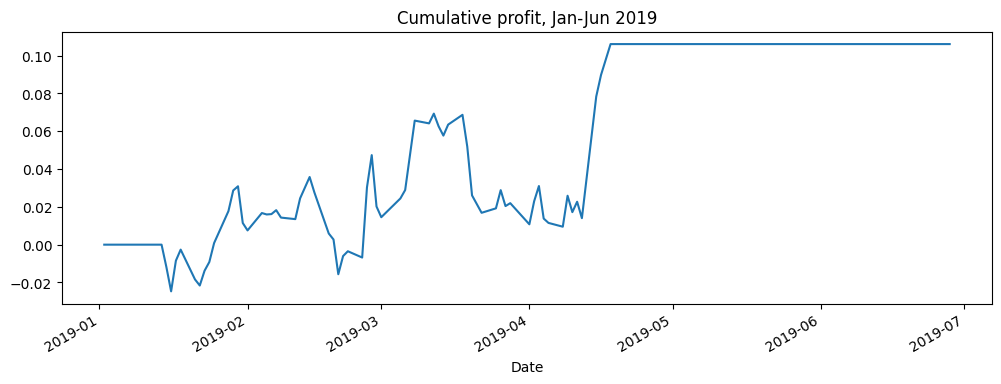

In [ ]:
pos = 0          # 0 = no trade, -1 = sold the spread, +1 = bought the spread
positions = []
for val in z:
    if pos == 0:
        if val > 2:
            pos = -1
        elif val < -2:
            pos = 1
    elif pos == -1 and val < 0.5:
        pos = 0
    elif pos == 1 and val > -0.5:
        pos = 0
    positions.append(pos)

positions = pd.Series(positions, index=z.index)

# profit each day = yesterday's position × today's change in the spread
daily_pnl = positions.shift(1) * spread_test.diff()
print("Total profit:", round(daily_pnl.sum() * 100, 2), "%")
print("Days in a trade:", (positions != 0).sum())

daily_pnl.cumsum().plot(figsize=(12, 4), title="Cumulative profit, Jan-Jun 2019")
plt.show()

   Trading starts  p-value  Half-life  Profit %
0      2019-01-01    0.006       10.9     10.21
1      2019-07-01    0.014       11.9     34.96
2      2020-01-01    0.003       14.2     10.96
3      2020-07-01    0.001       11.0    -12.11
4      2021-01-01    0.008       14.7      0.00
5      2021-07-01    0.011       11.4     14.15
6      2022-01-01    0.047       13.5      0.00
7      2022-07-01    0.044       16.0      0.00
8      2023-01-01    0.179        NaN      0.00
9      2023-07-01    0.806        NaN      0.00
10     2024-01-01    0.624        NaN      0.00
11     2024-07-01    0.482        NaN      0.00
12     2025-01-01    0.593        NaN      0.00
13     2025-07-01    0.827        NaN      0.00
14     2026-01-01    0.779        NaN      0.00
Total profit: 58.17 %


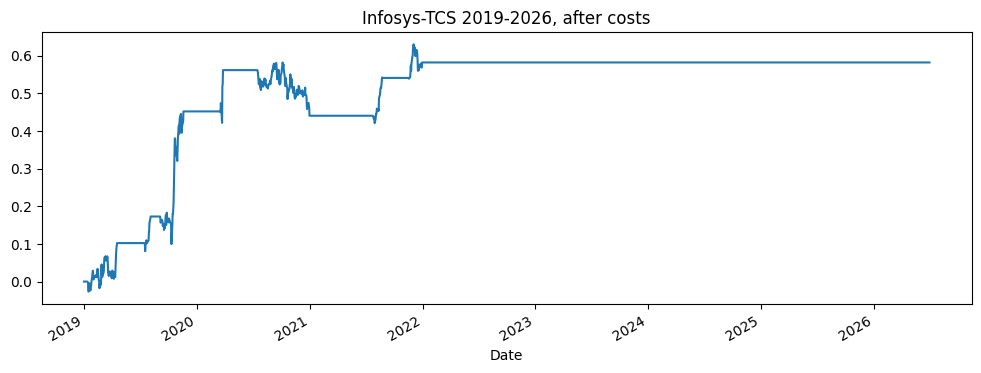

In [ ]:
def run_window(a, b, form, test, entry=2, exit=0.5, cost=0.002):
    # 1. still cointegrated? if not, don't trade
    _, p, _ = coint(form[a], form[b])
    if p > 0.05:
        return pd.Series(0.0, index=test.index), p, np.nan

    # 2. learn the numbers from the formation period
    h, c = np.polyfit(form[b], form[a], 1)
    s = form[a] - h * form[b] - c
    ds = s.diff().dropna()
    lag = s.shift(1).dropna()
    slope, intercept = np.polyfit(lag, ds, 1)
    if slope >= 0:
        return pd.Series(0.0, index=test.index), p, np.nan
    theta = -np.log(1 + slope)
    mu = -intercept / slope
    resid = ds - (intercept + slope * lag)
    sigma = resid.std() / np.sqrt(1 - np.exp(-2 * theta))

    # 3. trade the next 6 months
    s_test = test[a] - h * test[b] - c
    z = (s_test - mu) / sigma
    pos, positions = 0, []
    for val in z:
        if pos == 0:
            if val > entry: pos = -1
            elif val < -entry: pos = 1
        elif pos == -1 and val < exit: pos = 0
        elif pos == 1 and val > -exit: pos = 0
        positions.append(pos)
    positions = pd.Series(positions, index=z.index)
    positions.iloc[-1] = 0                      # close any open trade at the end

    pnl = (positions.shift(1) * s_test.diff()).fillna(0)
    trades = positions.diff().fillna(positions).abs()
    pnl = pnl - trades * cost                   # pay costs on every entry and exit
    return pnl, p, np.log(2) / theta


results, all_pnl = [], []
start = pd.Timestamp("2017-01-01")
while True:
    form_end = start + pd.DateOffset(years=2)
    test_end = form_end + pd.DateOffset(months=6)
    if test_end > logp.index[-1]:
        break
    form = logp.loc[start : form_end - pd.Timedelta(days=1)]
    test = logp.loc[form_end : test_end - pd.Timedelta(days=1)]
    pnl, p, hl = run_window("INFY.NS", "TCS.NS", form, test)
    all_pnl.append(pnl)
    hl_show = None if np.isnan(hl) else round(hl, 1)
    results.append((form_end.date(), round(p, 3), hl_show, round(pnl.sum() * 100, 2)))
    start += pd.DateOffset(months=6)

pnl_all = pd.concat(all_pnl)
print(pd.DataFrame(results, columns=["Trading starts", "p-value", "Half-life", "Profit %"]))
print("Total profit:", round(pnl_all.sum() * 100, 2), "%")

pnl_all.cumsum().plot(figsize=(12, 4), title="Infosys-TCS 2019-2026, after costs")
plt.show()

            Pair  Profit %  Worst drop %
4       INFY-TCS      58.2         -16.1
1    HCLTECH-TCS      37.9         -20.7
0   HCLTECH-INFY      12.4          -8.8
9    TECHM-WIPRO       8.0         -11.3
7      TCS-TECHM       6.2          -5.2
2  HCLTECH-TECHM       0.3         -12.1
5     INFY-TECHM       0.0           0.0
3  HCLTECH-WIPRO       0.0           0.0
8      TCS-WIPRO       0.0           0.0
6     INFY-WIPRO      -7.9         -14.4
Portfolio profit: 11.5 %
Sharpe ratio: 0.67


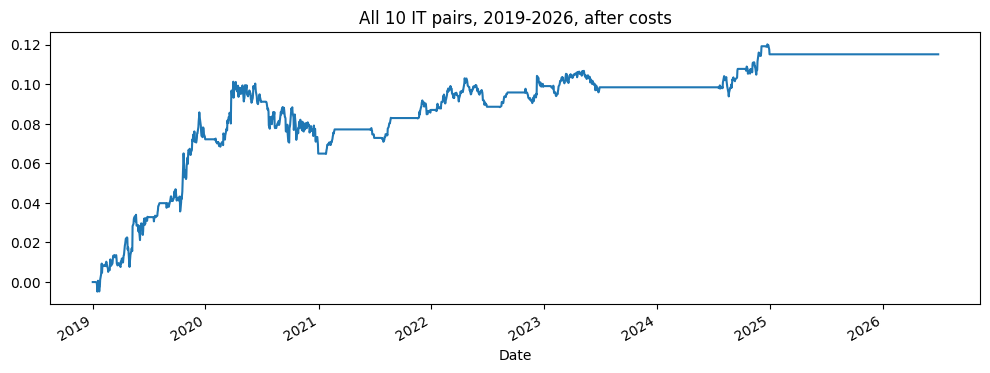

In [ ]:
def backtest_pair(a, b):
    pnls = []
    start = pd.Timestamp("2017-01-01")
    while True:
        form_end = start + pd.DateOffset(years=2)
        test_end = form_end + pd.DateOffset(months=6)
        if test_end > logp.index[-1]:
            break
        form = logp.loc[start : form_end - pd.Timedelta(days=1)]
        test = logp.loc[form_end : test_end - pd.Timedelta(days=1)]
        pnl, p, hl = run_window(a, b, form, test)
        pnls.append(pnl)
        start += pd.DateOffset(months=6)
    return pd.concat(pnls)

summary, pair_pnls = [], {}
for a, b in combinations(logp.columns, 2):
    s = backtest_pair(a, b)
    name = a.replace(".NS", "") + "-" + b.replace(".NS", "")
    pair_pnls[name] = s
    cum = s.cumsum()
    worst = (cum - cum.cummax()).min()
    summary.append((name, round(s.sum() * 100, 1), round(worst * 100, 1)))

print(pd.DataFrame(summary, columns=["Pair", "Profit %", "Worst drop %"])
      .sort_values("Profit %", ascending=False))

# split money equally across all 10 pairs
portfolio = pd.DataFrame(pair_pnls).mean(axis=1)
sharpe = portfolio.mean() / portfolio.std() * np.sqrt(252)
print("Portfolio profit:", round(portfolio.sum() * 100, 1), "%")
print("Sharpe ratio:", round(sharpe, 2))

portfolio.cumsum().plot(figsize=(12, 4), title="All 10 IT pairs, 2019-2026, after costs")
plt.show()

In [ ]:
def backtest_pair(a, b, **settings):
    pnls = []
    start = pd.Timestamp("2017-01-01")
    while True:
        form_end = start + pd.DateOffset(years=2)
        test_end = form_end + pd.DateOffset(months=6)
        if test_end > logp.index[-1]:
            break
        form = logp.loc[start : form_end - pd.Timedelta(days=1)]
        test = logp.loc[form_end : test_end - pd.Timedelta(days=1)]
        pnl, p, hl = run_window(a, b, form, test, **settings)
        pnls.append(pnl)
        start += pd.DateOffset(months=6)
    return pd.concat(pnls)

def portfolio_stats(**settings):
    pnls = {f"{a}-{b}": backtest_pair(a, b, **settings)
            for a, b in combinations(logp.columns, 2)}
    port = pd.DataFrame(pnls).mean(axis=1)
    sharpe = port.mean() / port.std() * np.sqrt(252)
    return round(port.sum() * 100, 1), round(sharpe, 2)

tests = [
    ("Normal (entry 2, cost 0.2%)", dict()),
    ("Double costs (0.4%)", dict(cost=0.004)),
    ("Enter earlier (z = 1.5)", dict(entry=1.5)),
    ("Enter later (z = 2.5)", dict(entry=2.5)),
]
rows = [(name, *portfolio_stats(**s)) for name, s in tests]
print(pd.DataFrame(rows, columns=["Setting", "Profit %", "Sharpe"]))

                       Setting  Profit %  Sharpe
0  Normal (entry 2, cost 0.2%)      11.5    0.67
1          Double costs (0.4%)      10.3    0.60
2      Enter earlier (z = 1.5)       8.8    0.46
3        Enter later (z = 2.5)      12.7    0.83


Number of trades: 31
          A      B       Entry  Days held  Half-life
0   HCLTECH   INFY  2019-01-14         14       11.2
1   HCLTECH   INFY  2019-04-24         39       11.2
2   HCLTECH   INFY  2019-10-24         46       12.2
3   HCLTECH   INFY  2021-06-18          8       15.3
4   HCLTECH    TCS  2019-04-01         58       10.5
5   HCLTECH    TCS  2019-11-11         34       12.9
6   HCLTECH    TCS  2020-07-20        115        8.3
7   HCLTECH    TCS  2021-01-25         19       10.2
8   HCLTECH    TCS  2021-06-24          4       10.2
9   HCLTECH    TCS  2022-01-28         17        8.4
10  HCLTECH    TCS  2022-08-11         15        9.5
11  HCLTECH    TCS  2022-11-21         29        9.5
12  HCLTECH    TCS  2023-03-14         72       13.0
13  HCLTECH    TCS  2024-07-18         44       14.9
14  HCLTECH    TCS  2024-10-15         35       14.9
15  HCLTECH    TCS  2024-12-20          6       14.9
16  HCLTECH  TECHM  2019-04-03         57       12.5
17  HCLTECH  TECHM  2019-

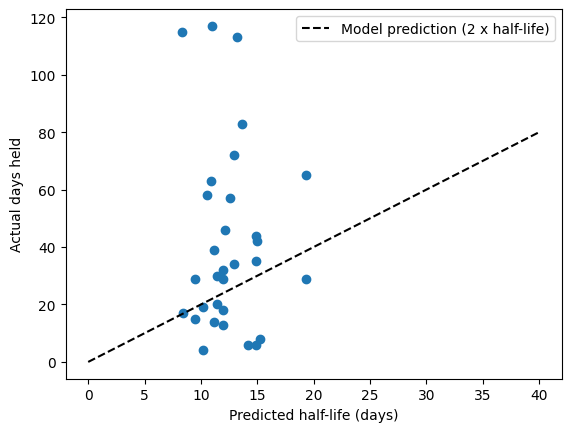

In [ ]:
def run_window(a, b, form, test, entry=2, exit=0.5, cost=0.002):
    _, p, _ = coint(form[a], form[b])
    if p > 0.05:
        return pd.Series(0.0, index=test.index), p, np.nan

    h, c = np.polyfit(form[b], form[a], 1)
    s = form[a] - h * form[b] - c
    ds = s.diff().dropna()
    lag = s.shift(1).dropna()
    slope, intercept = np.polyfit(lag, ds, 1)
    if slope >= 0:
        return pd.Series(0.0, index=test.index), p, np.nan
    theta = -np.log(1 + slope)
    mu = -intercept / slope
    resid = ds - (intercept + slope * lag)
    sigma = resid.std() / np.sqrt(1 - np.exp(-2 * theta))

    s_test = test[a] - h * test[b] - c
    z = (s_test - mu) / sigma
    pos, positions = 0, []
    for val in z:
        if pos == 0:
            if val > entry: pos = -1
            elif val < -entry: pos = 1
        elif pos == -1 and val < exit: pos = 0
        elif pos == 1 and val > -exit: pos = 0
        positions.append(pos)
    positions = pd.Series(positions, index=z.index)
    positions.iloc[-1] = 0

    # NEW: record how long each trade lasted
    in_trade = False
    for date, now in positions.items():
        if now != 0 and not in_trade:
            in_trade, start_day = True, date
        elif now == 0 and in_trade:
            in_trade = False
            days = len(positions.loc[start_day:date]) - 1
            trade_log.append((a.replace(".NS", ""), b.replace(".NS", ""),
                              start_day.date(), days, np.log(2) / theta))

    pnl = (positions.shift(1) * s_test.diff()).fillna(0)
    trades_made = positions.diff().fillna(positions).abs()
    pnl = pnl - trades_made * cost
    return pnl, p, np.log(2) / theta


trade_log = []
for a, b in combinations(logp.columns, 2):
    backtest_pair(a, b)

trades = pd.DataFrame(trade_log, columns=["A", "B", "Entry", "Days held", "Half-life"])
print("Number of trades:", len(trades))
print(trades.round(1))
print("Median days held:", trades["Days held"].median())
print("Median half-life x 2:", round(trades["Half-life"].median() * 2, 1))

plt.scatter(trades["Half-life"], trades["Days held"])
plt.plot([0, 40], [0, 80], "k--", label="Model prediction (2 x half-life)")
plt.xlabel("Predicted half-life (days)")
plt.ylabel("Actual days held")
plt.legend()
plt.show()

In [ ]:
def run_window(a, b, form, test, entry=2, exit=0.5, cost=0.002, max_hold=None):
    _, p, _ = coint(form[a], form[b])
    if p > 0.05:
        return pd.Series(0.0, index=test.index), p, np.nan

    h, c = np.polyfit(form[b], form[a], 1)
    s = form[a] - h * form[b] - c
    ds = s.diff().dropna()
    lag = s.shift(1).dropna()
    slope, intercept = np.polyfit(lag, ds, 1)
    if slope >= 0:
        return pd.Series(0.0, index=test.index), p, np.nan
    theta = -np.log(1 + slope)
    mu = -intercept / slope
    resid = ds - (intercept + slope * lag)
    sigma = resid.std() / np.sqrt(1 - np.exp(-2 * theta))
    hl_days = np.log(2) / theta

    s_test = test[a] - h * test[b] - c
    z = (s_test - mu) / sigma

    pos, held, blocked, positions = 0, 0, False, []
    for val in z:
        if blocked and abs(val) < entry:
            blocked = False                 # gap came back to normal, can trade again
        if pos == 0:
            held = 0
            if not blocked:
                if val > entry: pos = -1
                elif val < -entry: pos = 1
        else:
            held += 1
            if pos == -1 and val < exit: pos = 0
            elif pos == 1 and val > -exit: pos = 0
            elif max_hold is not None and held > max_hold * hl_days:
                pos = 0                     # TIME STOP: give up on this trade
                blocked = True              # TIME STOP: don't jump straight back in
        positions.append(pos)
    positions = pd.Series(positions, index=z.index)
    positions.iloc[-1] = 0

    in_trade = False
    for date, now in positions.items():
        if now != 0 and not in_trade:
            in_trade, start_day = True, date
        elif now == 0 and in_trade:
            in_trade = False
            days = len(positions.loc[start_day:date]) - 1
            trade_log.append((a.replace(".NS", ""), b.replace(".NS", ""),
                              start_day.date(), days, hl_days))

    pnl = (positions.shift(1) * s_test.diff()).fillna(0)
    trades_made = positions.diff().fillna(positions).abs()
    pnl = pnl - trades_made * cost
    return pnl, p, hl_days


In [ ]:
tests = [
    ("No time stop", dict()),
    ("Time stop 2x half-life", dict(max_hold=2)),
    ("Time stop 3x half-life", dict(max_hold=3)),
    ("Time stop 4x half-life", dict(max_hold=4)),
]
rows = []
for name, s in tests:
    trade_log.clear()
    profit, sharpe = portfolio_stats(**s)
    longest = max(t[3] for t in trade_log)
    rows.append((name, profit, sharpe, len(trade_log), longest))

print(pd.DataFrame(rows, columns=["Setting", "Profit %", "Sharpe",
                                  "Trades", "Longest trade (days)"]))

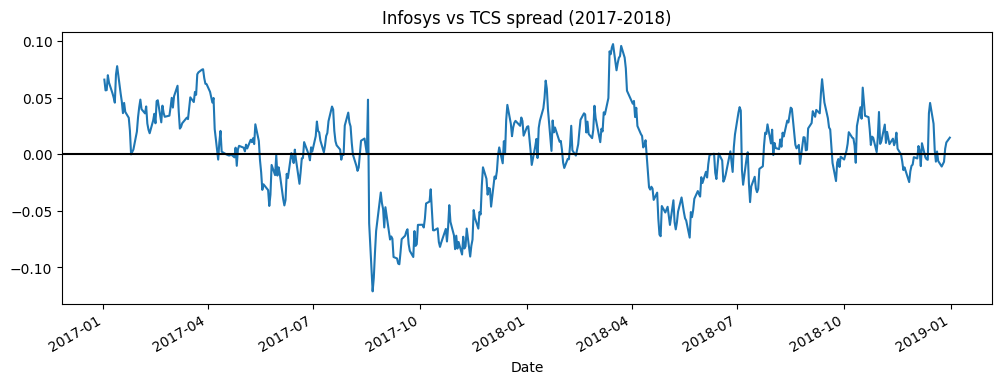

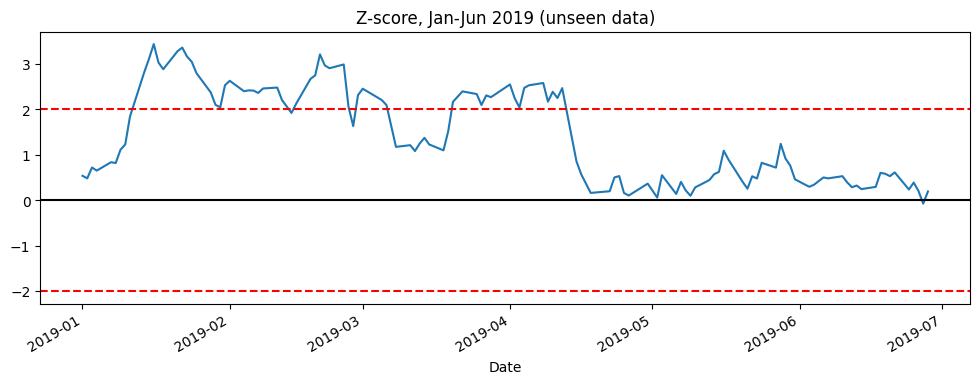

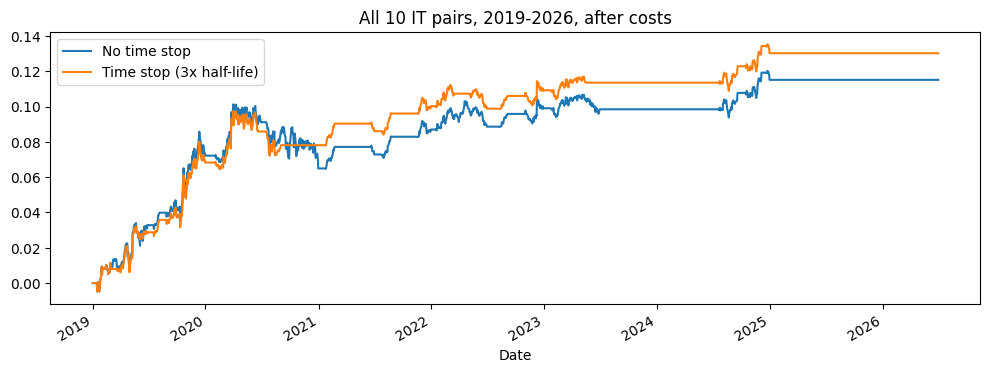

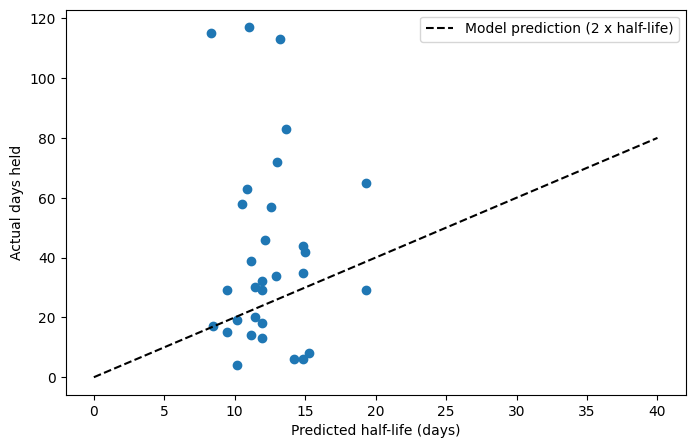

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
img = "/content/data"

# 1. Infosys-TCS spread
spread.plot(figsize=(12, 4), title="Infosys vs TCS spread (2017-2018)")
plt.axhline(0, color="black")
plt.savefig(f"{img}/spread.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Z-score 2019
z.plot(figsize=(12, 4), title="Z-score, Jan-Jun 2019 (unseen data)")
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")
plt.axhline(0, color="black")
plt.savefig(f"{img}/zscore_2019.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Portfolio, with and without time stop
def port_series(**s):
    pnls = {f"{a}-{b}": backtest_pair(a, b, **s) for a, b in combinations(logp.columns, 2)}
    return pd.DataFrame(pnls).mean(axis=1)

trade_log.clear()
base = port_series()
trade_log.clear()
ts = port_series(max_hold=3)
plt.figure(figsize=(12, 4))
base.cumsum().plot(label="No time stop")
ts.cumsum().plot(label="Time stop (3x half-life)")
plt.title("All 10 IT pairs, 2019-2026, after costs")
plt.legend()
plt.savefig(f"{img}/equity_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Holding time
plt.figure(figsize=(8, 5))
plt.scatter(trades["Half-life"], trades["Days held"])
plt.plot([0, 40], [0, 80], "k--", label="Model prediction (2 x half-life)")
plt.xlabel("Predicted half-life (days)")
plt.ylabel("Actual days held")
plt.legend()
plt.savefig(f"{img}/holding_time.png", dpi=150, bbox_inches="tight")
plt.show()